# 🚕 NYC Yellow Taxi 2015 — Data Visualization & Business Analytics

**Course:** Big Data Analysis — Information Systems 2026 I  
**Instructor:** Derbew Felasman  
**Dataset:** NYC TLC Yellow Taxi Trip Records — January 2015  
**Source:** PostgreSQL `taxi_db` → `trips` table (2,922,823 records)

---

This notebook connects directly to the PostgreSQL database loaded by the ETL pipeline
and produces **10 business analytics visualizations** covering demand patterns,
revenue analysis, and operational efficiency.

## 0. Setup — Libraries & Database Connection

In [3]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Add parent directory to path so we can reuse src/config.py
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import numpy as np

# ── Database configuration & connection ─────────────────────────────────────
try:
    from src.config import DB_CONFIG
except ImportError:
    DB_CONFIG = {
        'host': 'localhost', 'port': '5432', 'dbname': 'taxi_db',
        'user': 'postgres', 'password': '1234'
    }

try:
    import psycopg
    conn = psycopg.connect(**DB_CONFIG)
    print('Connected via psycopg (v3)')
except ImportError:
    import psycopg2 as psycopg
    conn = psycopg.connect(**DB_CONFIG)
    print('Connected via psycopg2')

# Helper: run SQL and return a DataFrame (auto-reconnecting if closed)
def query(sql, params=None):
    global conn
    if conn is None or conn.closed:
        conn = psycopg.connect(**DB_CONFIG)
    return pd.read_sql_query(sql, conn, params=params)

# Style defaults
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.alpha': 0.4,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
})

DOCS = os.path.abspath(os.path.join('..', 'docs')) if os.path.exists('../docs') else os.path.abspath('docs')
os.makedirs(DOCS, exist_ok=True)
print('Setup complete.')

Connected via psycopg (v3)
Setup complete.


## 1. Database Overview — Record Count & Table Sizes

In [4]:
# Total rows in trips
total = query("SELECT COUNT(*) AS total_trips FROM trips;").iloc[0, 0]
print(f'Total trips loaded: {total:,}')

# Table sizes on disk
sizes = query("""
    SELECT
        relname AS table_name,
        pg_size_pretty(pg_total_relation_size(relid)) AS total_size
    FROM pg_catalog.pg_statio_user_tables
    ORDER BY pg_total_relation_size(relid) DESC;
""")
print('\nTable sizes:')
display(sizes)

Total trips loaded: 2,922,823

Table sizes:


,table_name,total_size
0,trips,515 MB
1,vendors,24 kB
2,rate_codes,24 kB
3,payment_types,24 kB


## 2. Hourly Demand — When Do New Yorkers Ride? 🕐

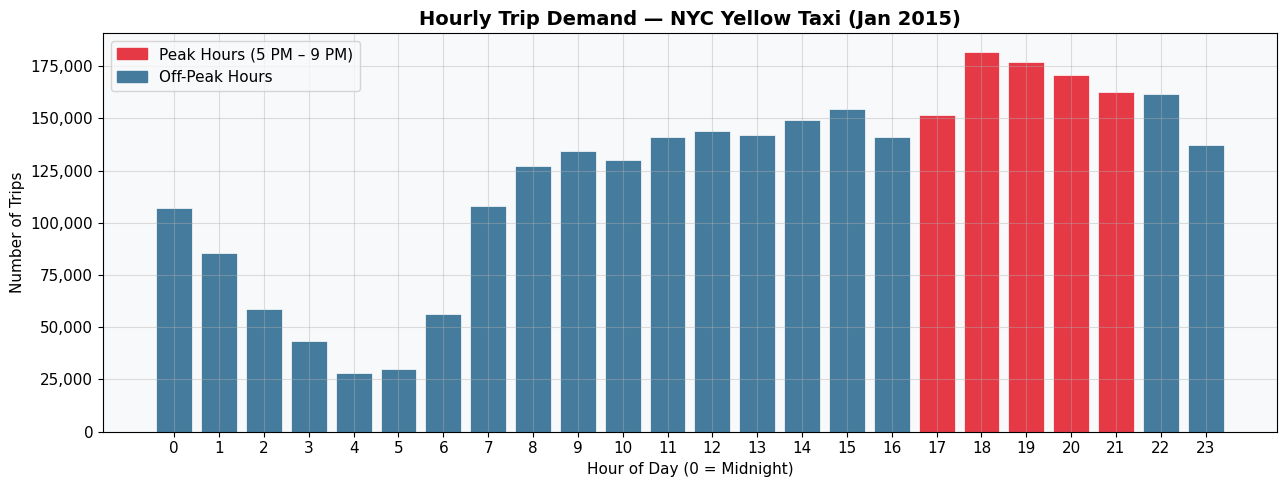

Peak hour: 18 h


In [3]:
hourly = query("""
    SELECT pickup_hour, COUNT(*) AS trip_count
    FROM trips
    GROUP BY pickup_hour
    ORDER BY pickup_hour;
""")

colors = ['#e63946' if h in range(17, 22) else '#457b9d' for h in hourly['pickup_hour']]

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(hourly['pickup_hour'], hourly['trip_count'], color=colors, edgecolor='white', linewidth=0.5)
ax.set_title('Hourly Trip Demand — NYC Yellow Taxi (Jan 2015)')
ax.set_xlabel('Hour of Day (0 = Midnight)')
ax.set_ylabel('Number of Trips')
ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
peak_patch = mpatches.Patch(color='#e63946', label='Peak Hours (5 PM – 9 PM)')
off_patch  = mpatches.Patch(color='#457b9d', label='Off-Peak Hours')
ax.legend(handles=[peak_patch, off_patch])
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_hourly_demand.png', dpi=150)
plt.show()
print('Peak hour:', hourly.loc[hourly['trip_count'].idxmax(), 'pickup_hour'], 'h')

## 3. Day-of-Week Demand — Weekday vs Weekend 📅

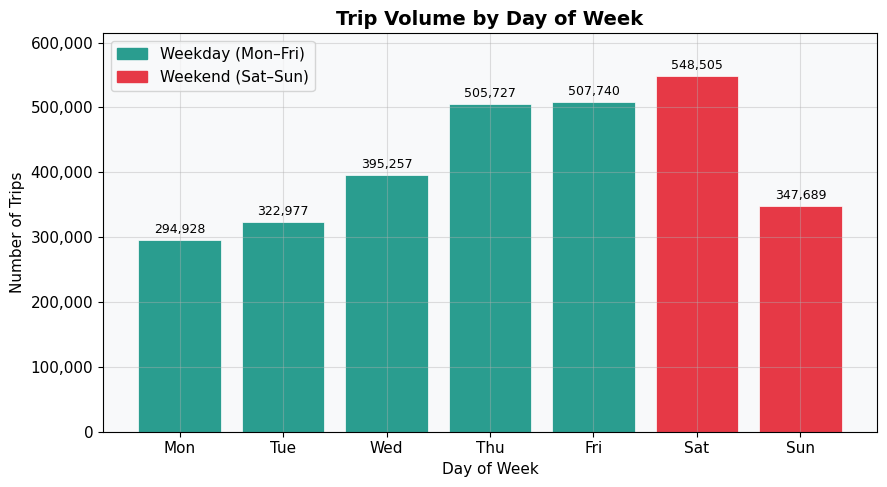

In [5]:
daily = query("""
    SELECT pickup_dow, COUNT(*) AS trip_count
    FROM trips
    GROUP BY pickup_dow
    ORDER BY pickup_dow;
""")

# In PostgreSQL / ETL: 0 = Sunday, 1 = Monday, ..., 6 = Saturday
dow_names = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}
daily['day_name'] = daily['pickup_dow'].map(dow_names)

# Order logically from Monday to Sunday
day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
daily['order'] = daily['day_name'].map(lambda d: day_order.index(d))
daily = daily.sort_values('order').reset_index(drop=True)

colors = ['#e63946' if d in ['Sat', 'Sun'] else '#2a9d8f' for d in daily['day_name']]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(daily['day_name'], daily['trip_count'], color=colors, edgecolor='white', linewidth=0.5)
ax.bar_label(bars, fmt=lambda x: f'{int(x):,}', padding=3, fontsize=9)
ax.set_title('Trip Volume by Day of Week')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Number of Trips')
ax.set_ylim(0, daily['trip_count'].max() * 1.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
wd = mpatches.Patch(color='#2a9d8f', label='Weekday (Mon–Fri)')
we = mpatches.Patch(color='#e63946', label='Weekend (Sat–Sun)')
ax.legend(handles=[wd, we])
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_day_of_week.png', dpi=150)
plt.show()

## 4. Revenue Analysis — Fare vs Tip vs Tolls 💰

,total_fare,total_tips,total_tolls,total_extras,total_taxes,grand_total
0,34573671.43,4490313.22,703773.46,902537.67,2287286.3,43003681.9


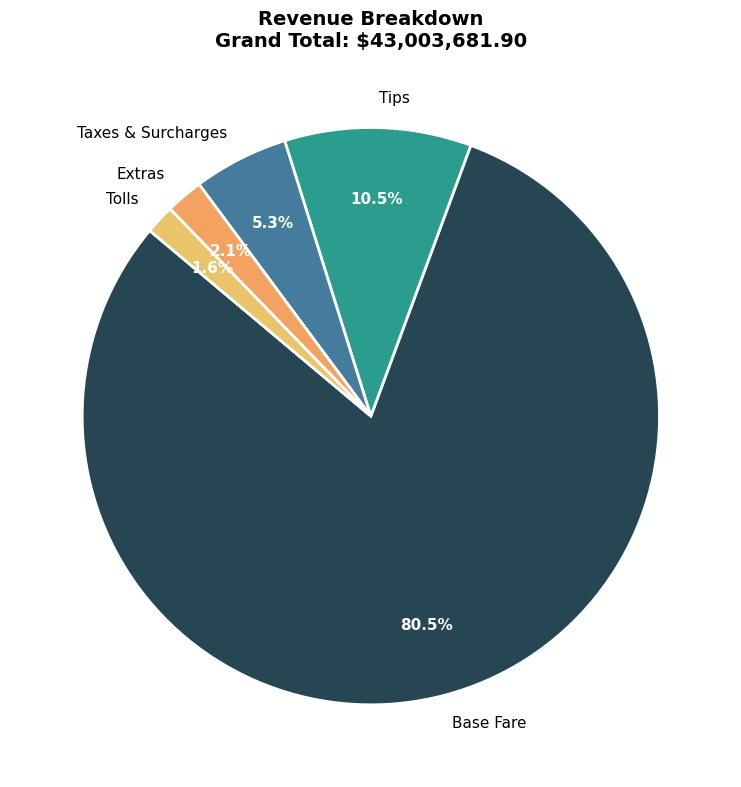

In [6]:
revenue = query("""
    SELECT
        ROUND(SUM(fare_amount)::numeric, 2)                         AS total_fare,
        ROUND(SUM(tip_amount)::numeric, 2)                          AS total_tips,
        ROUND(SUM(tolls_amount)::numeric, 2)                        AS total_tolls,
        ROUND(SUM(extra)::numeric, 2)                               AS total_extras,
        ROUND(SUM(mta_tax + improvement_surcharge)::numeric, 2)     AS total_taxes,
        ROUND(SUM(total_amount)::numeric, 2)                        AS grand_total
    FROM trips;
""")
display(revenue)

labels = ['Base Fare', 'Tips', 'Taxes & Surcharges', 'Extras', 'Tolls']
values = [
    float(revenue['total_fare'].iloc[0]),
    float(revenue['total_tips'].iloc[0]),
    float(revenue['total_taxes'].iloc[0]),
    float(revenue['total_extras'].iloc[0]),
    float(revenue['total_tolls'].iloc[0]),
]
clrs = ['#264653', '#2a9d8f', '#457b9d', '#f4a261', '#e9c46a']

fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    values, labels=labels, autopct='%1.1f%%',
    colors=clrs, startangle=140, pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_color('white')
    at.set_fontweight('bold')
ax.set_title(f'Revenue Breakdown\nGrand Total: ${float(revenue["grand_total"].iloc[0]):,.2f}')
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_revenue_breakdown.png', dpi=150)
plt.show()

## 5. Avg Fare & Tip by Hour of Day 📈

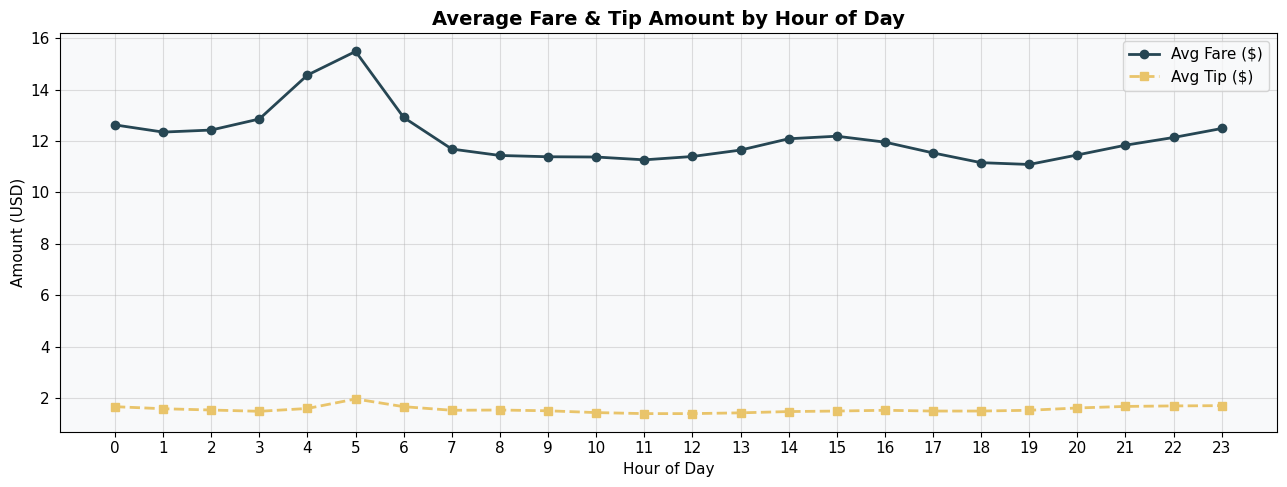

In [7]:
hourly_fare = query("""
    SELECT
        pickup_hour,
        ROUND(AVG(fare_amount)::numeric, 2) AS avg_fare,
        ROUND(AVG(tip_amount)::numeric, 2)  AS avg_tip
    FROM trips
    WHERE fare_amount > 0
    GROUP BY pickup_hour
    ORDER BY pickup_hour;
""")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(hourly_fare['pickup_hour'], hourly_fare['avg_fare'],
        marker='o', color='#264653', linewidth=2, label='Avg Fare ($)')
ax.plot(hourly_fare['pickup_hour'], hourly_fare['avg_tip'],
        marker='s', color='#e9c46a', linewidth=2, linestyle='--', label='Avg Tip ($)')
ax.set_title('Average Fare & Tip Amount by Hour of Day')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Amount (USD)')
ax.set_xticks(range(24))
ax.legend()
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_avg_fare_by_hour.png', dpi=150)
plt.show()

## 6. Payment Type Distribution 💳

,payment_name,trip_count,pct
0,Credit card,1812509,62.0
1,Cash,1101837,37.7
2,No charge,6626,0.2
3,Dispute,1851,0.1


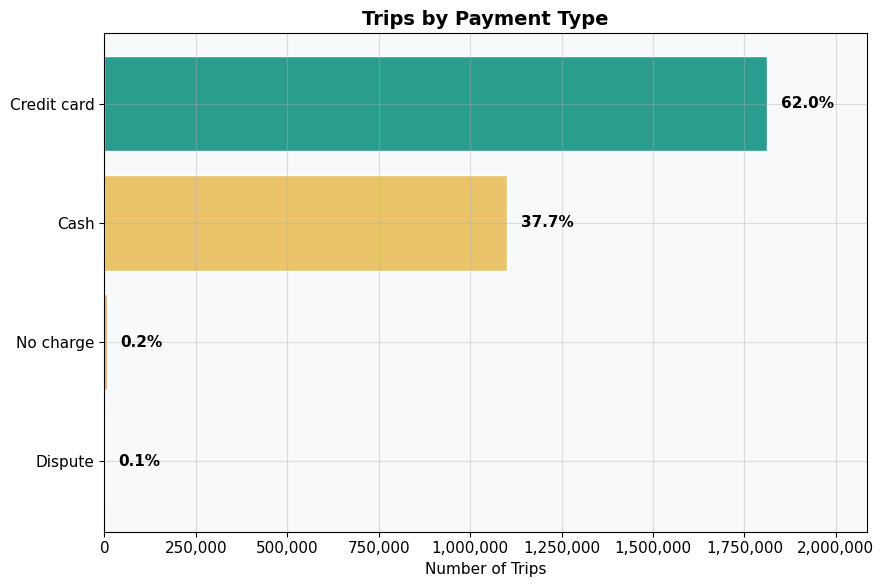

In [8]:
payment = query("""
    SELECT
        dp.description AS payment_name,
        COUNT(*) AS trip_count,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 1) AS pct
    FROM trips t
    JOIN payment_types dp ON t.payment_type_id = dp.payment_type_id
    GROUP BY dp.description
    ORDER BY trip_count DESC;
""")
display(payment)

clrs = ['#2a9d8f','#e9c46a','#f4a261','#e76f51','#264653','#457b9d']
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(payment['payment_name'], payment['trip_count'],
               color=clrs[:len(payment)], edgecolor='white')
for bar, pct in zip(bars, payment['pct']):
    ax.text(bar.get_width() + (payment['trip_count'].max() * 0.02), bar.get_y() + bar.get_height()/2,
            f'{pct}%', va='center', fontsize=11, fontweight='bold')
ax.set_title('Trips by Payment Type')
ax.set_xlabel('Number of Trips')
ax.set_xlim(0, payment['trip_count'].max() * 1.15)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_payment_types.png', dpi=150)
plt.show()

## 7. Trip Distance Distribution (0–30 miles) 🗺️

,distance_band,trip_count
0,0-1,697213
1,1-2,997511
2,2-3,481580
3,3-5,370727
4,5-10,239516
5,10-20,124684
6,20+,11555


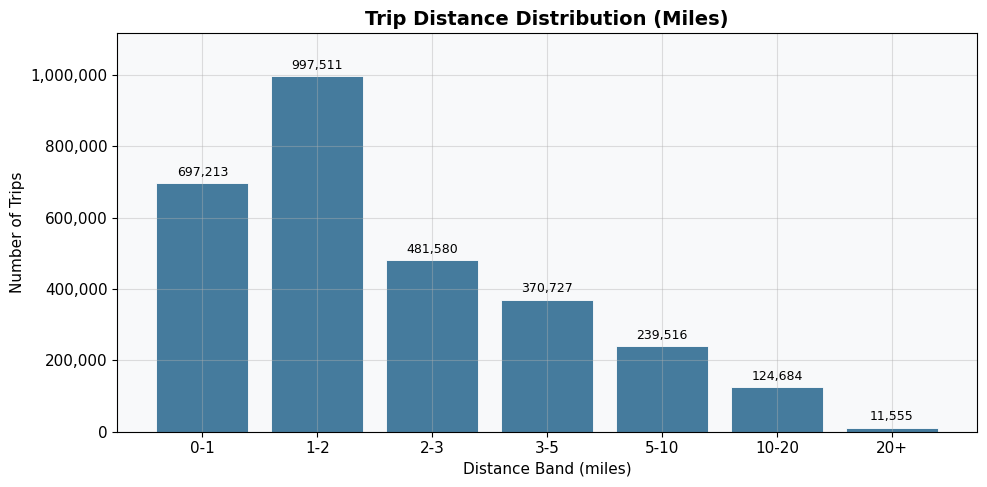

In [9]:
dist = query("""
    SELECT
        CASE
            WHEN trip_distance < 1   THEN '0-1'
            WHEN trip_distance < 2   THEN '1-2'
            WHEN trip_distance < 3   THEN '2-3'
            WHEN trip_distance < 5   THEN '3-5'
            WHEN trip_distance < 10  THEN '5-10'
            WHEN trip_distance < 20  THEN '10-20'
            ELSE '20+'
        END AS distance_band,
        COUNT(*) AS trip_count
    FROM trips
    WHERE trip_distance > 0 AND trip_distance <= 50
    GROUP BY distance_band
    ORDER BY MIN(trip_distance);
""")
display(dist)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(dist['distance_band'], dist['trip_count'],
              color='#457b9d', edgecolor='white', linewidth=0.6)
ax.bar_label(bars, fmt=lambda x: f'{int(x):,}', padding=3, fontsize=9)
ax.set_title('Trip Distance Distribution (Miles)')
ax.set_xlabel('Distance Band (miles)')
ax.set_ylabel('Number of Trips')
ax.set_ylim(0, dist['trip_count'].max() * 1.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_trip_distance.png', dpi=150)
plt.show()

## 8. Trip Duration Distribution ⏱️

,duration_band,trip_count
0,0-5,492170
1,5-10,966195
2,10-15,656007
3,15-20,366016
4,20-30,301865
5,30-45,106828
6,45-60,22819
7,60+,8357


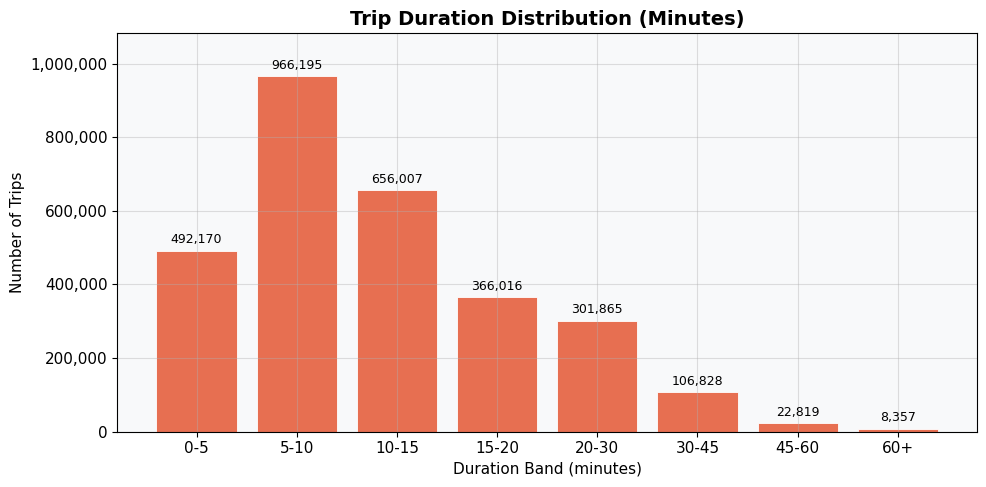

In [10]:
duration = query("""
    SELECT
        CASE
            WHEN trip_duration_min < 5   THEN '0-5'
            WHEN trip_duration_min < 10  THEN '5-10'
            WHEN trip_duration_min < 15  THEN '10-15'
            WHEN trip_duration_min < 20  THEN '15-20'
            WHEN trip_duration_min < 30  THEN '20-30'
            WHEN trip_duration_min < 45  THEN '30-45'
            WHEN trip_duration_min < 60  THEN '45-60'
            ELSE '60+'
        END AS duration_band,
        COUNT(*) AS trip_count
    FROM trips
    WHERE trip_duration_min > 0 AND trip_duration_min <= 120
    GROUP BY duration_band
    ORDER BY MIN(trip_duration_min);
""")
display(duration)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(duration['duration_band'], duration['trip_count'],
              color='#e76f51', edgecolor='white', linewidth=0.6)
ax.bar_label(bars, fmt=lambda x: f'{int(x):,}', padding=3, fontsize=9)
ax.set_title('Trip Duration Distribution (Minutes)')
ax.set_xlabel('Duration Band (minutes)')
ax.set_ylabel('Number of Trips')
ax.set_ylim(0, duration['trip_count'].max() * 1.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_trip_duration.png', dpi=150)
plt.show()

## 9. Vendor Performance Comparison 🏢

,vendor_name,total_trips,avg_fare,avg_distance,avg_duration_min,avg_tip
0,VeriFone Inc.,1547370,11.90,2.83,14.18,1.53
1,"Creative Mobile Technologies, LLC",1375453,11.75,2.75,12.32,1.55


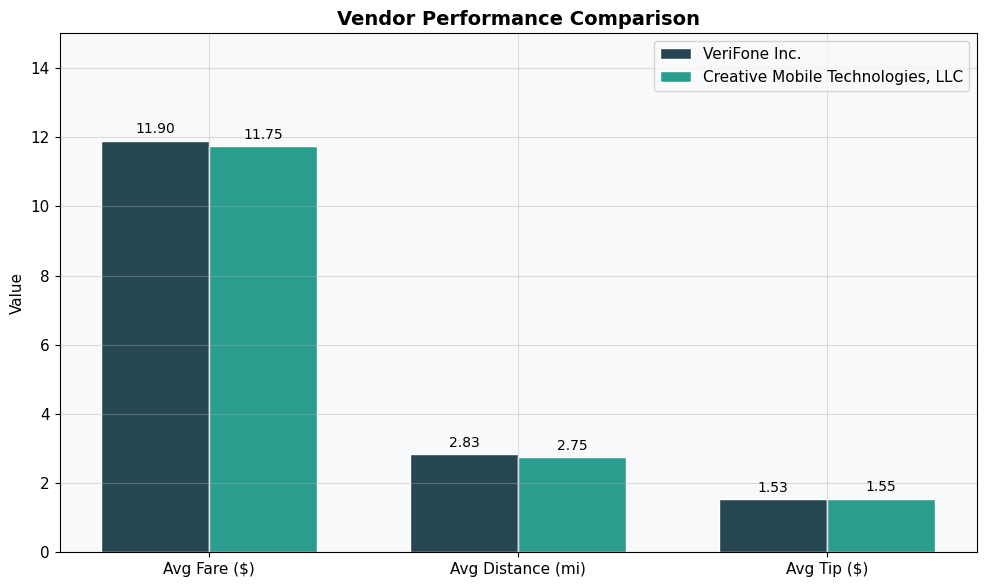

In [11]:
vendor = query("""
    SELECT
        dv.vendor_name,
        COUNT(*)                                      AS total_trips,
        ROUND(AVG(t.fare_amount)::numeric, 2)         AS avg_fare,
        ROUND(AVG(t.trip_distance)::numeric, 2)       AS avg_distance,
        ROUND(AVG(t.trip_duration_min)::numeric, 2)   AS avg_duration_min,
        ROUND(AVG(t.tip_amount)::numeric, 2)          AS avg_tip
    FROM trips t
    JOIN vendors dv ON t.vendor_id = dv.vendor_id
    GROUP BY dv.vendor_name
    ORDER BY total_trips DESC;
""")
display(vendor)

metrics = ['avg_fare', 'avg_distance', 'avg_tip']
labels  = ['Avg Fare ($)', 'Avg Distance (mi)', 'Avg Tip ($)']
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
for i, (_, row) in enumerate(vendor.iterrows()):
    vals = [float(row[m]) for m in metrics]
    bars = ax.bar(x + i * width, vals, width, label=row['vendor_name'],
                  color=['#264653', '#2a9d8f'][i % 2], edgecolor='white')
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=10)

ax.set_title('Vendor Performance Comparison')
ax.set_xticks(x + width / 2)
ax.set_xticklabels(labels)
ax.set_ylabel('Value')
ax.set_ylim(0, max(vendor['avg_fare'].astype(float).max() * 1.15, 15))
ax.legend()
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_vendor_comparison.png', dpi=150)
plt.show()

## 10. Heatmap — Avg Fare by Hour × Day of Week 🔥

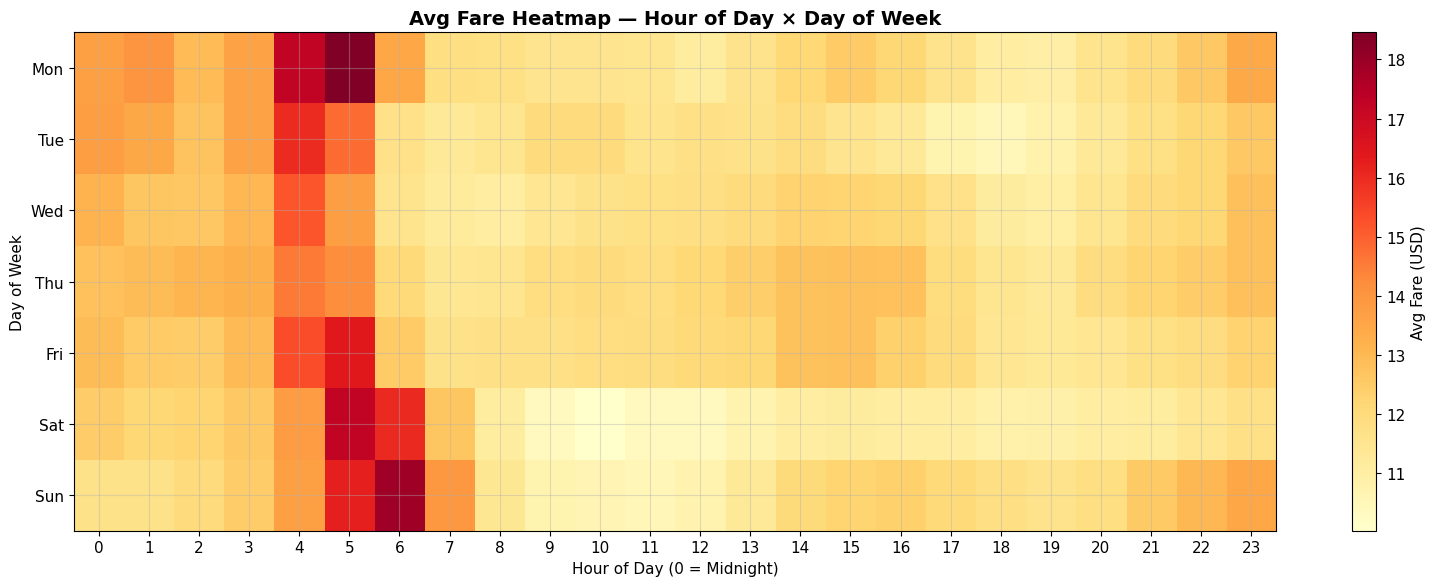

In [11]:
heat = query("""
    SELECT
        pickup_dow,
        pickup_hour,
        ROUND(AVG(fare_amount)::numeric, 2) AS avg_fare
    FROM trips
    WHERE fare_amount > 0
    GROUP BY pickup_dow, pickup_hour
    ORDER BY pickup_dow, pickup_hour;
""")

# In PostgreSQL / ETL: 0 = Sunday, 1 = Monday, ..., 6 = Saturday
dow_names = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}
heat['day_name'] = heat['pickup_dow'].map(dow_names)

day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
pivot = heat.pivot(index='day_name', columns='pickup_hour', values='avg_fare').reindex(day_order)

fig, ax = plt.subplots(figsize=(16, 6))
im = ax.imshow(pivot.values, aspect='auto', cmap='YlOrRd')
plt.colorbar(im, ax=ax, label='Avg Fare (USD)')
ax.set_title('Avg Fare Heatmap — Hour of Day × Day of Week')
ax.set_xlabel('Hour of Day (0 = Midnight)')
ax.set_ylabel('Day of Week')
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(len(day_order)))
ax.set_yticklabels(day_order)
plt.tight_layout()
plt.savefig(f'{DOCS}/viz_fare_heatmap.png', dpi=150)
plt.show()

## 11. Passenger Count — Solo vs Group Rides 👥

,passenger_count,trip_count,avg_fare,avg_tip
0,1,2058571,11.71,1.55
1,2,416682,12.31,1.53
2,3,121380,11.98,1.43
3,4,58217,12.11,1.34
4,5,162141,11.95,1.54
5,6,105832,11.73,1.49


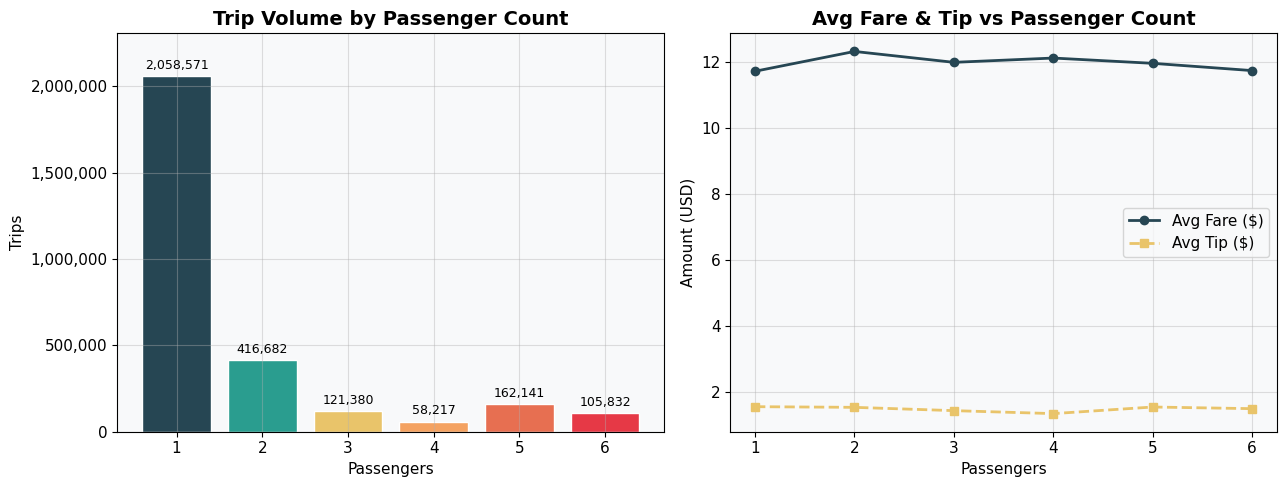

In [12]:
pax = query("""
    SELECT
        passenger_count,
        COUNT(*) AS trip_count,
        ROUND(AVG(fare_amount)::numeric, 2) AS avg_fare,
        ROUND(AVG(tip_amount)::numeric, 2)  AS avg_tip
    FROM trips
    WHERE passenger_count BETWEEN 1 AND 6
    GROUP BY passenger_count
    ORDER BY passenger_count;
""")
display(pax)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

clrs = ['#264653','#2a9d8f','#e9c46a','#f4a261','#e76f51','#e63946']
bars1 = ax1.bar(pax['passenger_count'].astype(str), pax['trip_count'],
                color=clrs[:len(pax)], edgecolor='white')
ax1.bar_label(bars1, fmt=lambda x: f'{int(x):,}', padding=3, fontsize=9)
ax1.set_title('Trip Volume by Passenger Count')
ax1.set_xlabel('Passengers')
ax1.set_ylabel('Trips')
ax1.set_ylim(0, pax['trip_count'].max() * 1.12)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

ax2.plot(pax['passenger_count'], pax['avg_fare'], marker='o', color='#264653',
         linewidth=2, label='Avg Fare ($)')
ax2.plot(pax['passenger_count'], pax['avg_tip'], marker='s', color='#e9c46a',
         linewidth=2, linestyle='--', label='Avg Tip ($)')
ax2.set_title('Avg Fare & Tip vs Passenger Count')
ax2.set_xlabel('Passengers')
ax2.set_ylabel('Amount (USD)')
ax2.legend()
ax2.set_xticks(pax['passenger_count'])

plt.tight_layout()
plt.savefig(f'{DOCS}/viz_passenger_analysis.png', dpi=150)
plt.show()

## 12. Business Insights Summary 📋

In [13]:
summary = query("""
    SELECT
        COUNT(*)                                            AS total_trips,
        ROUND(AVG(fare_amount)::numeric, 2)                 AS avg_fare_usd,
        ROUND(AVG(trip_distance)::numeric, 2)               AS avg_distance_miles,
        ROUND(AVG(trip_duration_min)::numeric, 2)           AS avg_duration_min,
        ROUND(AVG(tip_amount)::numeric, 2)                  AS avg_tip_usd,
        ROUND(SUM(total_amount)::numeric, 2)                AS total_revenue_usd,
        ROUND(AVG(passenger_count)::numeric, 2)             AS avg_passengers,
        MAX(pickup_hour)                                    AS max_hour_observed
    FROM trips;
""")
display(summary.T.rename(columns={0: 'Value'}))

print()
print('=' * 55)
print('  KEY BUSINESS INSIGHTS — NYC Yellow Taxi Jan 2015')
print('=' * 55)
s = summary.iloc[0]
print(f'  Total Trips Analyzed : {int(s.total_trips):>15,}')
print(f'  Total Revenue        : ${float(s.total_revenue_usd):>14,.2f}')
print(f'  Avg Fare per Trip    : ${float(s.avg_fare_usd):>14.2f}')
print(f'  Avg Tip per Trip     : ${float(s.avg_tip_usd):>14.2f}')
print(f'  Avg Trip Distance    : {float(s.avg_distance_miles):>13.2f} mi')
print(f'  Avg Trip Duration    : {float(s.avg_duration_min):>13.2f} min')
print(f'  Avg Passengers       : {float(s.avg_passengers):>14.2f}')
print('=' * 55)

,Value
total_trips,2922823.00
avg_fare_usd,11.83
avg_distance_miles,2.79
avg_duration_min,13.31
avg_tip_usd,1.54
total_revenue_usd,43003681.90
avg_passengers,1.69
max_hour_observed,23.00



  KEY BUSINESS INSIGHTS — NYC Yellow Taxi Jan 2015
  Total Trips Analyzed :       2,922,823
  Total Revenue        : $ 43,003,681.90
  Avg Fare per Trip    : $         11.83
  Avg Tip per Trip     : $          1.54
  Avg Trip Distance    :          2.79 mi
  Avg Trip Duration    :         13.31 min
  Avg Passengers       :           1.69


In [14]:
# Close connection when done
conn.close()
print('Database connection closed.')
print(f'All visualization PNGs saved to: {DOCS}/')

Database connection closed.
All visualization PNGs saved to: C:\Users\Wondmagegn\Desktop\Big Data Assignment\docs/
